In [2]:
import sys
from pathlib import Path

# add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# Baseline Model Results and Diagnostics

Performance metrics, calibration analysis, and statistical tests for all four baseline classifiers across three biomarker panels.

## Data Sources
- Metrics: `reports/baselines/baseline_metrics_tuned.csv`, `reports/baselines/baseline_metrics_untuned.csv`
- Calibration plots: `reports/baselines/calibration/`
- Saved models: `reports/baselines/models/`

In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

BASE_DIR = Path("..").resolve()
REPORTS_DIR = BASE_DIR / "reports" / "baselines"
CALIB_DIR = REPORTS_DIR / "calibration"

untuned_path = REPORTS_DIR / "baseline_metrics_untuned.csv"
tuned_path = REPORTS_DIR / "baseline_metrics_tuned.csv"


In [4]:
untuned = pd.read_csv(untuned_path)
tuned = pd.read_csv(tuned_path)

# Ensure consistent columns and labels
untuned["tuning"] = "untuned"
tuned["tuning"] = "tuned"

metrics = pd.concat([untuned, tuned], ignore_index=True)
metrics.head()



,panel,model,tuning,best_params,cv_auc,auc,brier,precision,npv,f1,sensitivity,specificity,threshold
0,PanelA_RenalDemo,logreg,untuned,{},NaN,0.818271,0.167473,0.791854,0.688345,0.798254,0.804759,0.670892,0.5
1,PanelA_RenalDemo,decision_tree,untuned,{},NaN,0.780705,0.183215,0.771491,0.674090,0.787618,0.804433,0.629310,0.5
2,PanelA_RenalDemo,knn,untuned,{},NaN,0.789656,0.179353,0.767643,0.678552,0.789165,0.811930,0.617647,0.5
3,PanelA_RenalDemo,svm_linear,untuned,{},NaN,0.818537,0.167295,0.788321,0.690842,0.798842,0.809648,0.661765,0.5
4,PanelB_CBC,logreg,untuned,{},NaN,0.804671,0.171964,0.773908,0.697227,0.798928,0.825619,0.624746,0.5


In [5]:
# Best model per panel and tuning by AUC
best_by_panel = (
    metrics.sort_values("auc", ascending=False)
    .groupby(["panel", "tuning"], as_index=False)
    .first()
    [["panel", "tuning", "model", "auc", "brier", "f1", "sensitivity", "specificity"]]
)

best_by_panel



,panel,tuning,model,auc,brier,f1,sensitivity,specificity
0,PanelA_RenalDemo,tuned,svm_linear,0.818507,0.167274,0.799872,0.811604,0.661258
1,PanelA_RenalDemo,untuned,svm_linear,0.818537,0.167295,0.798842,0.809648,0.661765
2,PanelB_CBC,tuned,logreg,0.804640,0.171998,0.797792,0.824316,0.623225
3,PanelB_CBC,untuned,logreg,0.804671,0.171964,0.798928,0.825619,0.624746
4,PanelC_Combined,tuned,svm_linear,0.819303,0.166442,0.805303,0.821708,0.659229
5,PanelC_Combined,untuned,svm_linear,0.819411,0.166391,0.805174,0.821708,0.658722


In [6]:
# tuned baseline models ranked by AUC
tuned_all = (
    metrics[metrics["tuning"] == "tuned"]
    .sort_values(["auc", "brier"], ascending=[False, True])
    [["panel", "model", "auc", "brier", "sensitivity", "specificity", "precision", "npv", "f1"]]
    .reset_index(drop=True)
)

tuned_display = tuned_all.copy()
tuned_display["panel"] = tuned_display["panel"].str.replace("PanelA_RenalDemo", "A (Renal)").str.replace("PanelB_CBC", "B (CBC)").str.replace("PanelC_Combined", "C (Combined)")
tuned_display["model"] = tuned_display["model"].str.replace("logreg", "Logistic Reg").str.replace("decision_tree", "Decision Tree").str.replace("svm_linear", "Linear SVM")

print("Table 4.1: Tuned Baseline Models (Ranked by AUC)")
tuned_display.round(3)


Table 4.1: Tuned Baseline Models (Ranked by AUC)


,panel,model,auc,brier,sensitivity,specificity,precision,npv,f1
0,C (Combined),Linear SVM,0.819,0.166,0.822,0.659,0.790,0.704,0.805
1,C (Combined),Logistic Reg,0.819,0.167,0.813,0.665,0.791,0.695,0.801
2,A (Renal),Linear SVM,0.819,0.167,0.812,0.661,0.788,0.693,0.800
3,A (Renal),Logistic Reg,0.818,0.167,0.805,0.668,0.791,0.688,0.798
4,B (CBC),Logistic Reg,0.805,0.172,0.824,0.623,0.773,0.695,0.798
5,B (CBC),Linear SVM,0.804,0.172,0.827,0.622,0.773,0.698,0.799
6,C (Combined),knn,0.798,0.177,0.814,0.632,0.775,0.686,0.794
7,A (Renal),knn,0.797,0.176,0.821,0.616,0.769,0.689,0.794
8,B (CBC),knn,0.788,0.180,0.826,0.596,0.761,0.688,0.792
9,A (Renal),Decision Tree,0.784,0.182,0.818,0.623,0.771,0.687,0.794


In [7]:
# Full Table: All 24 Configurations (Tuned + Untuned) sorted by AUC, then Brier
all_configs = (
    metrics
    .sort_values(["auc", "brier"], ascending=[False, True])
    [["panel", "model", "tuning", "auc", "brier", "sensitivity", "specificity", "precision", "npv", "f1"]]
    .reset_index(drop=True)
)

# Format for display
all_display = all_configs.copy()
all_display["panel"] = all_display["panel"].str.replace("PanelA_RenalDemo", "A").str.replace("PanelB_CBC", "B").str.replace("PanelC_Combined", "C")
all_display["model"] = all_display["model"].str.replace("logreg", "LR").str.replace("decision_tree", "DT").str.replace("svm_linear", "SVM")

print("Full Table: All 24 Baseline Configurations (Ranked by AUC, then Brier)")
print("=" * 90)
print("Top 10 configurations:")
all_display.head(10).round(3)


Full Table: All 24 Baseline Configurations (Ranked by AUC, then Brier)
Top 10 configurations:


,panel,model,tuning,auc,brier,sensitivity,specificity,precision,npv,f1
0,C,SVM,untuned,0.819,0.166,0.822,0.659,0.789,0.704,0.805
1,C,SVM,tuned,0.819,0.166,0.822,0.659,0.790,0.704,0.805
2,C,LR,untuned,0.819,0.167,0.813,0.668,0.792,0.696,0.802
3,C,LR,tuned,0.819,0.167,0.813,0.665,0.791,0.695,0.801
4,A,SVM,untuned,0.819,0.167,0.810,0.662,0.788,0.691,0.799
5,A,SVM,tuned,0.819,0.167,0.812,0.661,0.788,0.693,0.800
6,A,LR,tuned,0.818,0.167,0.805,0.668,0.791,0.688,0.798
7,A,LR,untuned,0.818,0.167,0.805,0.671,0.792,0.688,0.798
8,B,LR,untuned,0.805,0.172,0.826,0.625,0.774,0.697,0.799
9,B,LR,tuned,0.805,0.172,0.824,0.623,0.773,0.695,0.798


In [8]:
# Full 24-row table (for appendix reference)
print("Complete Table: All 24 Configurations")
print("=" * 90)
all_display.round(3)


Complete Table: All 24 Configurations


,panel,model,tuning,auc,brier,sensitivity,specificity,precision,npv,f1
0,C,SVM,untuned,0.819,0.166,0.822,0.659,0.789,0.704,0.805
1,C,SVM,tuned,0.819,0.166,0.822,0.659,0.790,0.704,0.805
2,C,LR,untuned,0.819,0.167,0.813,0.668,0.792,0.696,0.802
3,C,LR,tuned,0.819,0.167,0.813,0.665,0.791,0.695,0.801
4,A,SVM,untuned,0.819,0.167,0.810,0.662,0.788,0.691,0.799
5,A,SVM,tuned,0.819,0.167,0.812,0.661,0.788,0.693,0.800
6,A,LR,tuned,0.818,0.167,0.805,0.668,0.791,0.688,0.798
7,A,LR,untuned,0.818,0.167,0.805,0.671,0.792,0.688,0.798
8,B,LR,untuned,0.805,0.172,0.826,0.625,0.774,0.697,0.799
9,B,LR,tuned,0.805,0.172,0.824,0.623,0.773,0.695,0.798


/var/folders/vk/4m7_md257wg416ynxtlk0hdm0000gn/T/ipykernel_33072/1907912419.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Panel A\n(Renal)', 'Panel B\n(CBC)', 'Panel C\n(Combined)'])


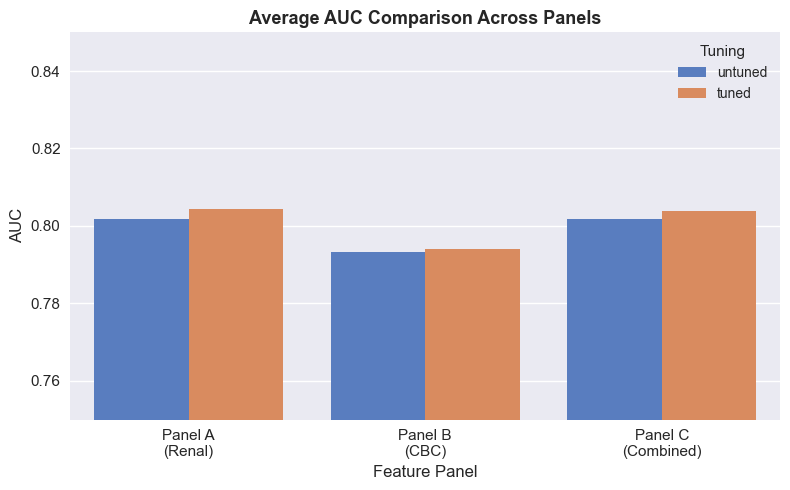

In [9]:
# Figure 4.1: AUC comparison across panels (tuned vs untuned)
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=metrics,
    x="panel",
    y="auc",
    hue="tuning",
    palette=["#4878d0", "#ee854a"],  # Blue for tuned, orange for untuned
    errorbar=None,
    ax=ax,
)

ax.set_title("Average AUC Comparison Across Panels", fontsize=13, fontweight='bold')
ax.set_xlabel("Feature Panel", fontsize=12)
ax.set_ylabel("AUC", fontsize=12)
ax.set_ylim(0.75, 0.85)  # Focus on relevant range
ax.tick_params(axis='both', labelsize=11)
ax.legend(title="Tuning", fontsize=10, title_fontsize=11, loc='upper right')

# Cleaner x-axis labels
ax.set_xticklabels(['Panel A\n(Renal)', 'Panel B\n(CBC)', 'Panel C\n(Combined)'])

plt.tight_layout()
plt.show()


In [10]:
# Tuned vs untuned delta per model/panel
pivot = metrics.pivot_table(
    index=["panel", "model"],
    columns="tuning",
    values="auc",
)

pivot["auc_delta"] = pivot.get("tuned") - pivot.get("untuned")
pivot.sort_values("auc_delta", ascending=False).head(10)



,tuning,tuned,untuned,auc_delta
panel,model,,,
PanelC_Combined,knn,0.798350,0.790470,0.007880
PanelA_RenalDemo,knn,0.797017,0.789656,0.007360
PanelB_CBC,knn,0.787617,0.781050,0.006567
PanelA_RenalDemo,decision_tree,0.783711,0.780705,0.003006
PanelC_Combined,decision_tree,0.778739,0.777804,0.000935
PanelA_RenalDemo,logreg,0.818286,0.818271,0.000014
PanelC_Combined,logreg,0.819231,0.819256,-0.000025
PanelA_RenalDemo,svm_linear,0.818507,0.818537,-0.000030
PanelB_CBC,logreg,0.804640,0.804671,-0.000030


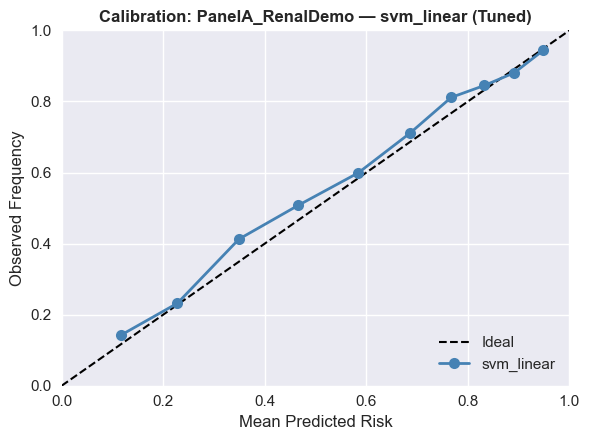

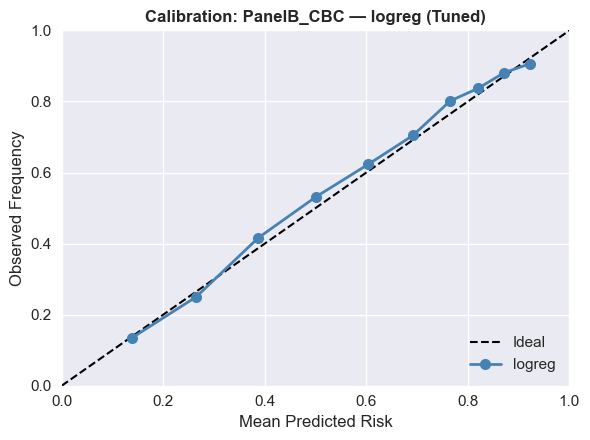

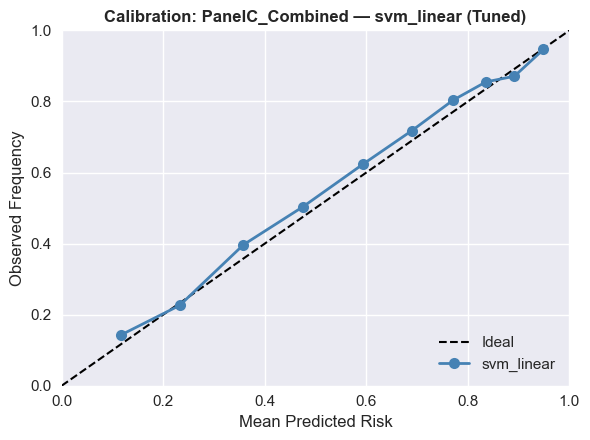

In [11]:
# Regenerate calibration curves with larger fonts 
from sklearn.calibration import calibration_curve
import joblib
from models.baselines.baseline_utils import load_dataset, load_panels, temporal_split

# Load data
raw_df = load_dataset(str(BASE_DIR / "data" / "clean" / "processed_dataset.csv"))
panels_def = load_panels(str(BASE_DIR / "data" / "clean" / "feature_panels.json"))
MODELS_DIR = REPORTS_DIR / "models"

best_tuned_rows = best_by_panel[best_by_panel["tuning"] == "tuned"]

# Generate separate calibration figures
for _, row in best_tuned_rows.iterrows():
    panel = row["panel"]
    model_name = row["model"]
    
    # Load model and get predictions
    model_path = MODELS_DIR / f"{panel}_{model_name}_tuned.joblib"
    if not model_path.exists():
        print(f"Missing: {model_path}")
        continue
    
    model = joblib.load(model_path)
    split = temporal_split(raw_df, panels_def[panel])
    y_prob = model.predict_proba(split.x_test.to_numpy())[:, 1]
    y_test = split.y_test.to_numpy()
    
    # Compute calibration curve
    frac_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
    
    # Individual figure
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Ideal')
    ax.plot(mean_pred, frac_pos, 'o-', color='steelblue', lw=2, markersize=8, label=model_name)
    ax.set_xlabel("Mean Predicted Risk", fontsize=12)
    ax.set_ylabel("Observed Frequency", fontsize=12)
    ax.set_title(f"Calibration: {panel} — {model_name} (Tuned)", fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=11)
    ax.tick_params(axis='both', labelsize=11)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    plt.tight_layout()
    plt.show()



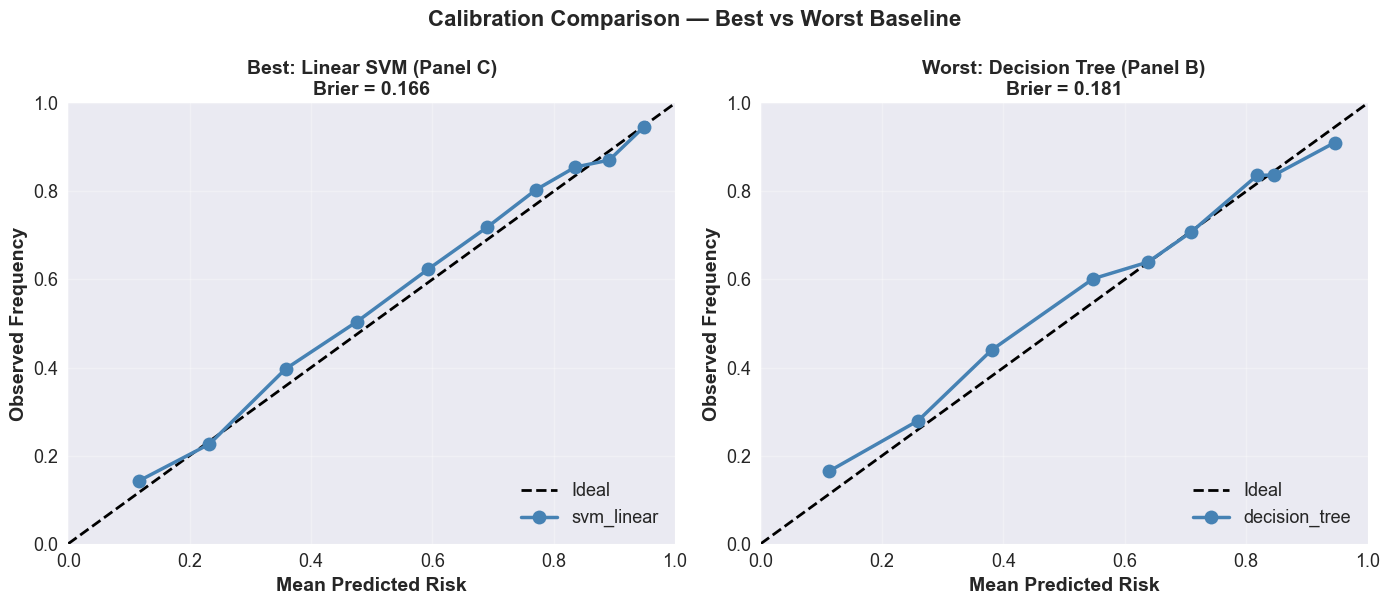

In [12]:
# Figure 4.1: Best vs Worst Calibration Comparison (for dissertation)
# Best: Panel C Linear SVM (Brier = 0.166)
# Worst: Panel B Decision Tree (Brier = 0.181)

comparisons = [
    ("PanelC_Combined", "svm_linear", "Best: Linear SVM (Panel C)\nBrier = 0.166"),
    ("PanelB_CBC", "decision_tree", "Worst: Decision Tree (Panel B)\nBrier = 0.181"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for idx, (panel, model_name, title) in enumerate(comparisons):
    model_path = MODELS_DIR / f"{panel}_{model_name}_tuned.joblib"
    model = joblib.load(model_path)
    
    split = temporal_split(raw_df, panels_def[panel])
    y_prob = model.predict_proba(split.x_test.to_numpy())[:, 1]
    y_test = split.y_test.to_numpy()
    
    frac_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
    
    ax = axes[idx]
    ax.plot([0, 1], [0, 1], 'k--', lw=2, label='Ideal')
    ax.plot(mean_pred, frac_pos, 'o-', color='steelblue', lw=2.5, markersize=10, label=model_name)
    ax.set_xlabel("Mean Predicted Risk", fontsize=14, fontweight='bold')
    ax.set_ylabel("Observed Frequency", fontsize=14, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=13)
    ax.tick_params(axis='both', labelsize=13)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    ax.grid(True, alpha=0.3)

fig.suptitle("Calibration Comparison — Best vs Worst Baseline", fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


## Diagnostic Figures

Confusion matrices, ROC curves, and precision-recall curves for the best tuned model per panel.

In [13]:
import joblib
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    roc_auc_score,
)

from models.baselines.baseline_utils import load_dataset, load_panels, temporal_split

raw_df = load_dataset(str(BASE_DIR / "data" / "clean" / "processed_dataset.csv"))
panels_def = load_panels(str(BASE_DIR / "data" / "clean" / "feature_panels.json"))
MODELS_DIR = REPORTS_DIR / "models"

# best tuned model per panel by AUC
best_tuned = (
    metrics[metrics["tuning"] == "tuned"]
    .sort_values("auc", ascending=False)
    .groupby("panel", as_index=False)
    .first()
)

print("Best tuned models per panel:")
print(best_tuned[["panel", "model", "auc", "brier"]])


Best tuned models per panel:
              panel       model       auc     brier
0  PanelA_RenalDemo  svm_linear  0.818507  0.167274
1        PanelB_CBC      logreg  0.804640  0.171998
2   PanelC_Combined  svm_linear  0.819303  0.166442



=== PanelA_RenalDemo — svm_linear (tuned) ===


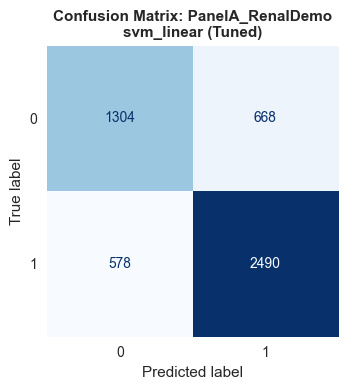

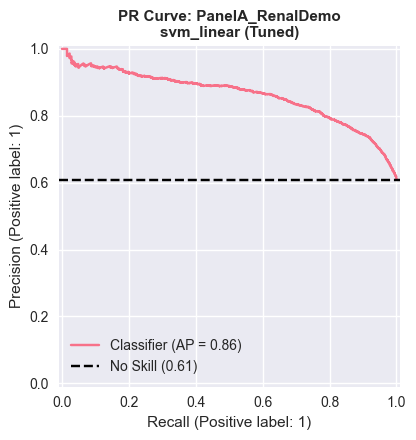


=== PanelB_CBC — logreg (tuned) ===


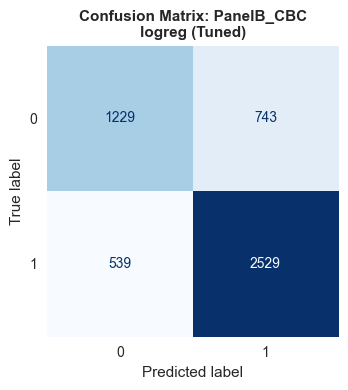

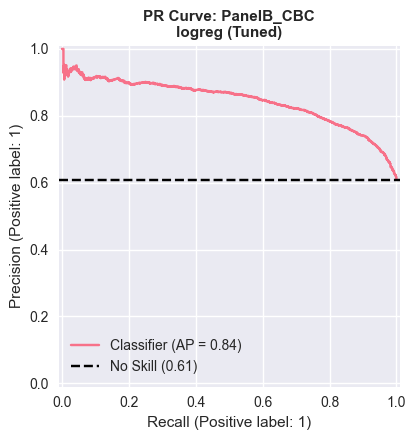


=== PanelC_Combined — svm_linear (tuned) ===


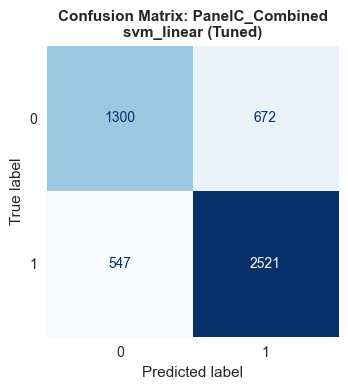

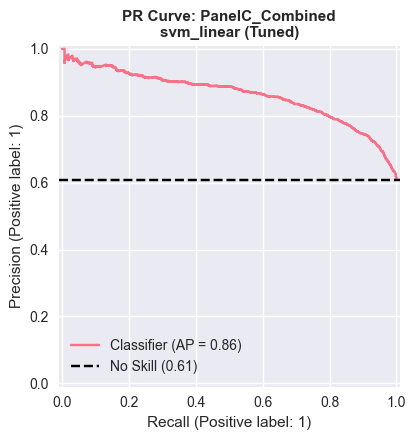

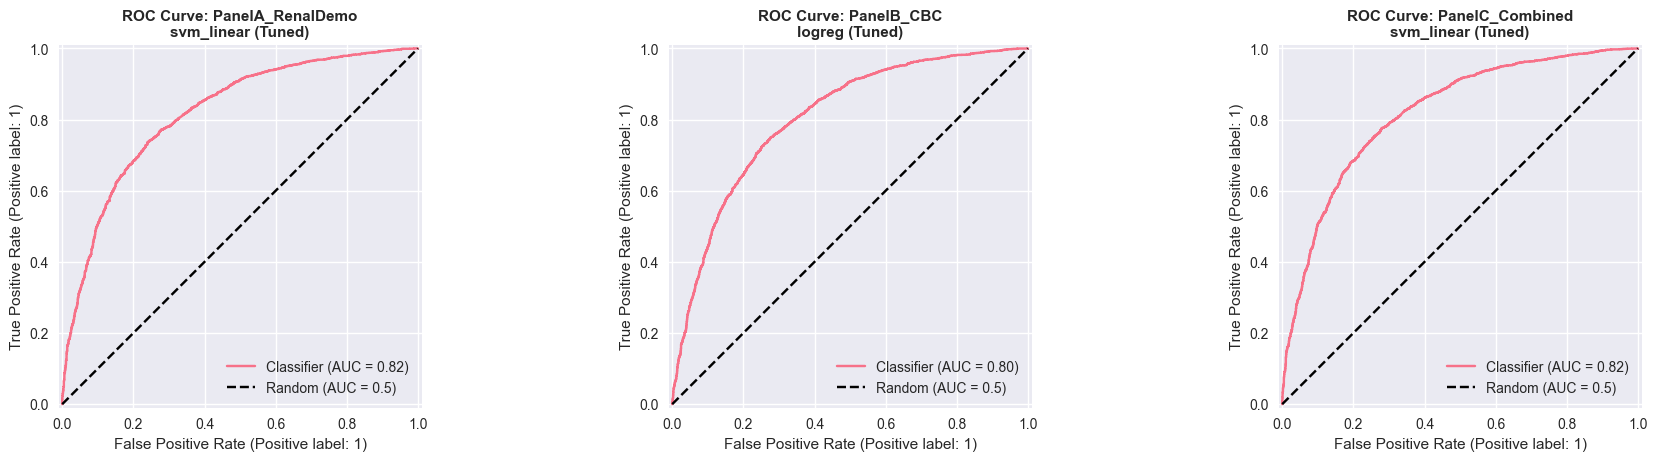

In [14]:
# Generate diagnostic figures for each panel
# First, collect all data for ROC curves to plot them together
roc_data = []

for _, row in best_tuned.iterrows():
    panel = row["panel"]
    model_name = row["model"]
    tuning = row["tuning"]
    
    # Load the saved trained model
    model_path = MODELS_DIR / f"{panel}_{model_name}_{tuning}.joblib"
    if not model_path.exists():
        print(f"Model not found: {model_path}")
        continue
    
    model = joblib.load(model_path)
    print(f"\n=== {panel} — {model_name} ({tuning}) ===")
    
    # Get test data for predictions
    split = temporal_split(raw_df, panels_def[panel])
    x_test = split.x_test.to_numpy()
    y_test = split.y_test.to_numpy()
    
    # Generate predictions
    y_prob = model.predict_proba(x_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    
    # Store ROC data for combined plot
    roc_data.append({
        'panel': panel,
        'model_name': model_name,
        'tuning': tuning,
        'y_test': y_test,
        'y_prob': y_prob,
        'y_pred': y_pred
    })

    # Figure 1: Confusion Matrix
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Confusion Matrix: {panel}\n{model_name} ({tuning.capitalize()})", fontsize=11, fontweight='bold')
    ax.grid(False)
    plt.tight_layout()
    plt.show()

    # Figure 2: Precision-Recall Curve
    fig, ax = plt.subplots(figsize=(6, 4.5))
    PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=ax)
    prevalence = y_test.mean()
    ax.axhline(y=prevalence, color='k', linestyle='--', label=f'No Skill ({prevalence:.2f})')
    ax.set_title(f"PR Curve: {panel}\n{model_name} ({tuning.capitalize()})", fontsize=11, fontweight='bold')
    ax.legend(loc='lower left', fontsize=10)
    ax.tick_params(axis='both', labelsize=10)
    plt.tight_layout()
    plt.show()

# Combined ROC Curves in one horizontal panel
n_panels = len(roc_data)
fig, axes = plt.subplots(1, n_panels, figsize=(6 * n_panels, 4.5), constrained_layout=True)
if n_panels == 1:
    axes = [axes]

for idx, data in enumerate(roc_data):
    ax = axes[idx]
    RocCurveDisplay.from_predictions(data['y_test'], data['y_prob'], ax=ax)
    ax.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')
    ax.set_title(f"ROC Curve: {data['panel']}\n{data['model_name']} ({data['tuning'].capitalize()})", 
                 fontsize=11, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10)
    ax.tick_params(axis='both', labelsize=10)

fig.get_layout_engine().set(w_pad=0.3, wspace=0.15)
plt.show()


## Statistical Analysis

Bootstrap 95% confidence intervals, panel comparison significance testing, and logistic regression coefficient analysis.

In [15]:
# bootstrap 95% CIs for AUC (all tuned models)
from scipy.stats import bootstrap
from sklearn.metrics import roc_auc_score

ci_results = []
for _, row in tuned.iterrows():
    panel, model_name = row["panel"], row["model"]
    model = joblib.load(MODELS_DIR / f"{panel}_{model_name}_tuned.joblib")
    split = temporal_split(raw_df, panels_def[panel])
    y_test, y_prob = split.y_test.to_numpy(), model.predict_proba(split.x_test.to_numpy())[:, 1]
    
    res = bootstrap((y_test, y_prob), lambda y, p: roc_auc_score(y, p), 
                    n_resamples=2000, paired=True, random_state=42)
    
    ci_results.append({
        'Panel': panel.replace('PanelA_RenalDemo', 'A').replace('PanelB_CBC', 'B').replace('PanelC_Combined', 'C'),
        'Model': model_name.replace('logreg', 'LR').replace('decision_tree', 'DT').replace('svm_linear', 'SVM'),
        'AUC': row['auc'],
        'Brier': row['brier'],
        '95% CI': f"[{res.confidence_interval.low:.3f}, {res.confidence_interval.high:.3f}]"
    })

ci_df = pd.DataFrame(ci_results).sort_values(by=['AUC', 'Brier'], ascending=False).reset_index(drop=True)
print("AUC with 95% Bootstrap CIs (n=2000)")
ci_df.round(3)


AUC with 95% Bootstrap CIs (n=2000)


,Panel,Model,AUC,Brier,95% CI
0,C,SVM,0.819,0.166,"[0.807, 0.831]"
1,C,LR,0.819,0.167,"[0.807, 0.831]"
2,A,SVM,0.819,0.167,"[0.806, 0.830]"
3,A,LR,0.818,0.167,"[0.806, 0.830]"
4,B,LR,0.805,0.172,"[0.792, 0.817]"
5,B,SVM,0.804,0.172,"[0.792, 0.816]"
6,C,knn,0.798,0.177,"[0.786, 0.811]"
7,A,knn,0.797,0.176,"[0.784, 0.809]"
8,B,knn,0.788,0.180,"[0.775, 0.801]"
9,A,DT,0.784,0.182,"[0.771, 0.797]"


In [16]:
# Panel A vs Panel B bootstrap significance test
model_a = joblib.load(MODELS_DIR / "PanelA_RenalDemo_svm_linear_tuned.joblib")
model_b = joblib.load(MODELS_DIR / "PanelB_CBC_logreg_tuned.joblib")
split_a = temporal_split(raw_df, panels_def["PanelA_RenalDemo"])
split_b = temporal_split(raw_df, panels_def["PanelB_CBC"])

y_test = split_a.y_test.to_numpy()
y_prob_a = model_a.predict_proba(split_a.x_test.to_numpy())[:, 1]
y_prob_b = model_b.predict_proba(split_b.x_test.to_numpy())[:, 1]

auc_a, auc_b = roc_auc_score(y_test, y_prob_a), roc_auc_score(y_test, y_prob_b)
obs_diff = auc_a - auc_b

rng = np.random.default_rng(42)
n_boot, n = 5000, len(y_test)
boot_diffs = []
for _ in range(n_boot):
    idx = rng.integers(0, n, size=n)
    if len(np.unique(y_test[idx])) < 2: continue
    boot_diffs.append(roc_auc_score(y_test[idx], y_prob_a[idx]) - roc_auc_score(y_test[idx], y_prob_b[idx]))

boot_diffs = np.array(boot_diffs)
p_value = np.mean(boot_diffs <= 0) * 2

print(f"Panel A (Linear SVM) AUC: {auc_a:.4f}")
print(f"Panel B (Logistic Reg) AUC: {auc_b:.4f}")
print(f"ΔAUC: {obs_diff:.4f} (95% CI: [{np.percentile(boot_diffs, 2.5):.4f}, {np.percentile(boot_diffs, 97.5):.4f}])")
print(f"P-value: {p_value:.4f} ({'Significant' if p_value < 0.05 else 'Not significant'} at α=0.05)")


Panel A (Linear SVM) AUC: 0.8185
Panel B (Logistic Reg) AUC: 0.8046
ΔAUC: 0.0139 (95% CI: [0.0089, 0.0187])
P-value: 0.0000 (Significant at α=0.05)


In [17]:
# logistic regression coefficients with odds ratios
def lr_coef_table(panel_key, panel_label):
    model = joblib.load(MODELS_DIR / f"{panel_key}_logreg_tuned.joblib")
    return (pd.DataFrame({'Feature': panels_def[panel_key], 'Coef': model.coef_[0], 'OR': np.exp(model.coef_[0])})
            .assign(Direction=lambda x: np.where(x['Coef'] > 0, 'positive', 'negative'))
            .sort_values('Coef', key=abs, ascending=False)
            .round({'Coef': 3, 'OR': 2}))

print("Panel A (Renal) — LR Coefficients")
display(lr_coef_table("PanelA_RenalDemo", "A"))
print("\nPanel B (CBC) — LR Coefficients")
display(lr_coef_table("PanelB_CBC", "B"))


Panel A (Renal) — LR Coefficients


,Feature,Coef,OR,Direction
6,RIDAGEYR,0.916,2.50,positive
0,ACR_mg_g_log,0.673,1.96,positive
1,BMXBMI,0.554,1.74,positive
16,sex_female,-0.360,0.70,negative
12,race_non_hispanic_black,0.356,1.43,positive
13,race_non_hispanic_white,-0.317,0.73,negative
8,URXUMA,-0.221,0.80,negative
10,race_mexican_american,-0.217,0.81,negative
9,eGFR,-0.208,0.81,negative
15,race_other_race,0.207,1.23,positive



Panel B (CBC) — LR Coefficients


,Feature,Coef,OR,Direction
5,RIDAGEYR,1.171,3.23,positive
0,BMXBMI,0.493,1.64,positive
8,race_non_hispanic_black,0.348,1.42,positive
12,sex_female,-0.315,0.73,negative
9,race_non_hispanic_white,-0.299,0.74,negative
6,race_mexican_american,-0.257,0.77,negative
11,race_other_race,0.179,1.20,positive
7,race_non_hispanic_asian,0.164,1.18,positive
10,race_other_hispanic,-0.138,0.87,negative
3,LBXRDW,0.125,1.13,positive


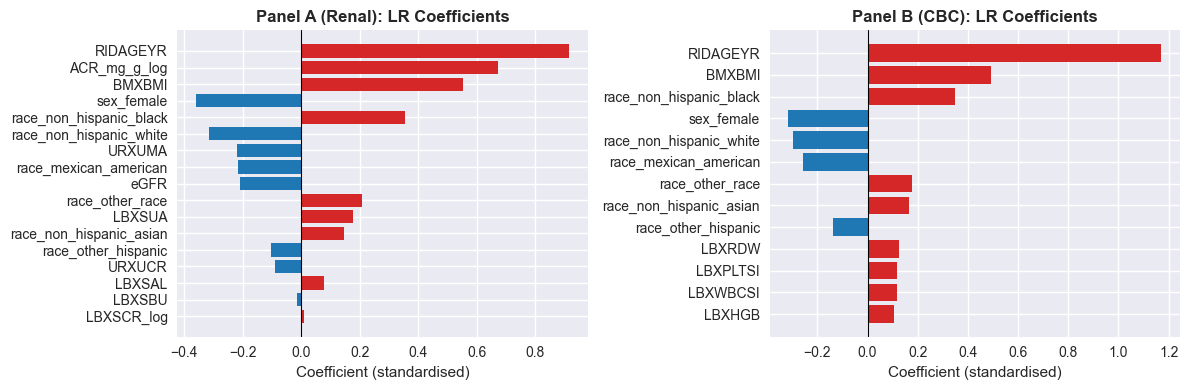

Red = increased HTN risk, Blue = decreased HTN risk.


In [18]:
# coefficient bar charts
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (panel_key, title) in zip(axes, [("PanelA_RenalDemo", "Panel A (Renal)"), ("PanelB_CBC", "Panel B (CBC)")]):
    df = lr_coef_table(panel_key, title)
    colors = ['#d62728' if c > 0 else '#1f77b4' for c in df['Coef']]
    ax.barh(df['Feature'], df['Coef'], color=colors)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('Coefficient (standardised)')
    ax.set_title(f'{title}: LR Coefficients', fontweight='bold')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()
print("Red = increased HTN risk, Blue = decreased HTN risk.")


In [19]:
# creatinine-eGFR correlation (explains attenuated creatinine coefficient)
split = temporal_split(raw_df, panels_def["PanelA_RenalDemo"])
corr = split.x_train[['LBXSCR_log', 'eGFR']].corr().iloc[0, 1]
print(f"Correlation between LBXSCR_log and eGFR: {corr:.3f}")


Correlation between LBXSCR_log and eGFR: -0.743


Panel A: Relative Feature Contribution (sum of |coef|)
  Demographic     3.174  (68.3%)
  Biomarker       1.472  (31.7%)


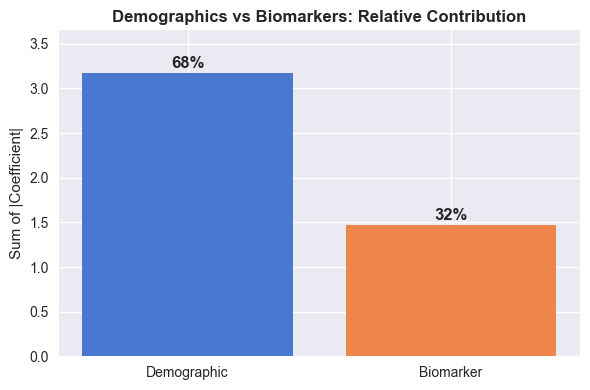

In [20]:
# relative contribution: demographics vs biomarkers
coef_a = lr_coef_table("PanelA_RenalDemo", "A")

DEMOGRAPHICS = {'RIDAGEYR', 'BMXBMI', 'sex_female', 
                'race_non_hispanic_black', 'race_non_hispanic_white', 
                'race_mexican_american', 'race_other_race', 
                'race_non_hispanic_asian', 'race_other_hispanic'}

coef_a['Type'] = coef_a['Feature'].apply(lambda f: 'Demographic' if f in DEMOGRAPHICS else 'Biomarker')

contrib = coef_a.groupby('Type')['Coef'].apply(lambda x: np.abs(x).sum()).sort_values(ascending=False)
total = contrib.sum()

print("Panel A: Relative Feature Contribution (sum of |coef|)")
for t, val in contrib.items():
    print(f"  {t:15} {val:.3f}  ({100*val/total:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
plot_order = ['Demographic', 'Biomarker']
plot_vals = [contrib.get(t, 0) for t in plot_order]
bars = ax.bar(plot_order, plot_vals, color=['#4878d0', '#ee854a'])
ax.set_ylabel('Sum of |Coefficient|')
ax.set_title('Demographics vs Biomarkers: Relative Contribution', fontweight='bold')
for bar, val in zip(bars, plot_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, 
            f'{100*val/total:.0f}%', ha='center', fontweight='bold', fontsize=12)
ax.set_ylim(0, max(plot_vals) * 1.15)
plt.tight_layout()
plt.show()


In [21]:
# parsimonious model: age + BMI + eGFR only
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

minimal_features = ['RIDAGEYR', 'BMXBMI', 'eGFR']

split = temporal_split(raw_df, panels_def["PanelA_RenalDemo"])
X_train_full = split.x_train
X_test_full = split.x_test
y_train, y_test = split.y_train.to_numpy(), split.y_test.to_numpy()

available = [f for f in minimal_features if f in X_train_full.columns]
X_train_min = X_train_full[available].to_numpy()
X_test_min = X_test_full[available].to_numpy()

lr_minimal = LogisticRegression(max_iter=1000, random_state=42)
lr_minimal.fit(X_train_min, y_train)
y_prob_min = lr_minimal.predict_proba(X_test_min)[:, 1]

lr_full = joblib.load(MODELS_DIR / "PanelA_RenalDemo_logreg_tuned.joblib")
y_prob_full = lr_full.predict_proba(X_test_full.to_numpy())[:, 1]

auc_min = roc_auc_score(y_test, y_prob_min)
auc_full = roc_auc_score(y_test, y_prob_full)
brier_min = brier_score_loss(y_test, y_prob_min)
brier_full = brier_score_loss(y_test, y_prob_full)

# discriminative ability above chance (AUC=0.5 baseline)
disc_retained = 100 * (auc_min - 0.5) / (auc_full - 0.5)

print(f"Parsimonious Model ({len(available)} features): AUC={auc_min:.4f}, Brier={brier_min:.4f}")
print(f"Full Panel A (17 features):      AUC={auc_full:.4f}, Brier={brier_full:.4f}")
print(f"Retained {disc_retained:.1f}% of discriminative ability above chance with {len(available)}/{len(panels_def['PanelA_RenalDemo'])} features.")


Parsimonious Model (3 features): AUC=0.7931, Brier=0.1774
Full Panel A (17 features):      AUC=0.8183, Brier=0.1674
Retained 92.1% of discriminative ability above chance with 3/17 features.


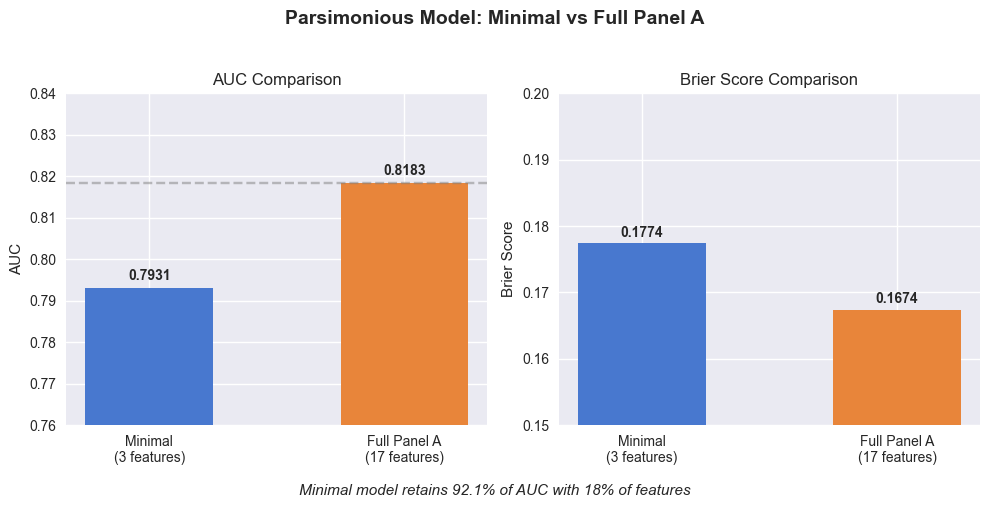

In [22]:
import matplotlib.pyplot as plt
import numpy as np

minimal_auc = 0.7931
full_auc = 0.8183
minimal_brier = 0.1774
full_brier = 0.1674

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("Parsimonious Model: Minimal vs Full Panel A", fontsize=14, fontweight='bold')

# AUC comparison
bars1 = ax1.bar(["Minimal\n(3 features)", "Full Panel A\n(17 features)"],
                [minimal_auc, full_auc], color=["#4878CF", "#E8853A"], width=0.5)
ax1.set_ylabel("AUC")
ax1.set_title("AUC Comparison")
ax1.set_ylim(0.76, 0.84)
ax1.axhline(y=full_auc, color='grey', linestyle='--', alpha=0.5)
for bar, val in zip(bars1, [minimal_auc, full_auc]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f"{val:.4f}", ha='center', fontweight='bold')

# Brier comparison
bars2 = ax2.bar(["Minimal\n(3 features)", "Full Panel A\n(17 features)"],
                [minimal_brier, full_brier], color=["#4878CF", "#E8853A"], width=0.5)
ax2.set_ylabel("Brier Score")
ax2.set_title("Brier Score Comparison")
ax2.set_ylim(0.15, 0.20)
for bar, val in zip(bars2, [minimal_brier, full_brier]):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f"{val:.4f}", ha='center', fontweight='bold')

retained = (minimal_auc - 0.5) / (full_auc - 0.5) * 100
fig.text(0.5, 0.01, f"Minimal model retains {retained:.1f}% of AUC with 18% of features",
         ha='center', fontsize=11, style='italic')

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.savefig("parsimonious_comparison.png", dpi=300, bbox_inches='tight')
plt.show()